In [1]:
# Cellule 1 — Imports & Setup
import os
import json
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR

# Device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"✅ Device : {device}")
if device == 'cuda':
    print(f"   GPU : {torch.cuda.get_device_name(0)}")

✅ Device : cpu


In [5]:
# Cellule 2 — Chemins & Paramètres

# Chemins
DATA_ROOT  = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\archive'
CROP_ROOT  = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\crops'
MODEL_DIR  = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\models'

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(CROP_ROOT, exist_ok=True)

# Paramètres
SPLITS      = ['train', 'valid', 'test']
CLASS_NAMES = ['space-empty', 'space-occupied']
IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_WORKERS = 0
EPOCHS      = 5

print("✅ Paramètres configurés")
print(f"   DATA_ROOT  : {DATA_ROOT}")
print(f"   CROP_ROOT  : {CROP_ROOT}")
print(f"   MODEL_DIR  : {MODEL_DIR}")

✅ Paramètres configurés
   DATA_ROOT  : C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\archive
   CROP_ROOT  : C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\crops
   MODEL_DIR  : C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\models


In [6]:
# Cellule 3 — Extraction des crops depuis les bounding boxes

def extract_crops(split):
    ann_path = os.path.join(DATA_ROOT, split, '_annotations.coco.json')
    img_dir  = os.path.join(DATA_ROOT, split)
    out_dirs = {
        1: os.path.join(CROP_ROOT, split, 'space-empty'),
        2: os.path.join(CROP_ROOT, split, 'space-occupied')
    }
    for d in out_dirs.values():
        os.makedirs(d, exist_ok=True)

    with open(ann_path, 'r') as f:
        coco = json.load(f)

    id2file = {img['id']: img['file_name'] for img in coco['images']}

    saved, skipped = 0, 0
    for ann in coco['annotations']:
        cat_id = ann['category_id']
        if cat_id not in (1, 2):
            skipped += 1
            continue

        img_path = os.path.join(img_dir, id2file[ann['image_id']])
        x, y, w, h = [int(v) for v in ann['bbox']]

        if w < 5 or h < 5:
            skipped += 1
            continue

        img = cv2.imread(img_path)
        if img is None:
            skipped += 1
            continue

        H, W = img.shape[:2]
        x1, y1 = max(0, x), max(0, y)
        x2, y2 = min(W, x + w), min(H, y + h)

        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            skipped += 1
            continue

        out_name = f"{ann['id']}.jpg"
        out_path = os.path.join(out_dirs[cat_id], out_name)
        cv2.imwrite(out_path, crop)
        saved += 1

    print(f"  [{split}] Crops sauvegardés : {saved} | Ignorés : {skipped}")

print("⏳ Extraction des crops (peut prendre quelques minutes)...")
for split in SPLITS:
    extract_crops(split)
print("✅ Extraction terminée")

# Vérification
print("\n📊 Répartition des crops :")
for split in SPLITS:
    for cls in CLASS_NAMES:
        path = os.path.join(CROP_ROOT, split, cls)
        n = len(os.listdir(path))
        print(f"  {split}/{cls} : {n}")

⏳ Extraction des crops (peut prendre quelques minutes)...
  [train] Crops sauvegardés : 497856 | Ignorés : 0
  [valid] Crops sauvegardés : 143316 | Ignorés : 0
  [test] Crops sauvegardés : 70684 | Ignorés : 0
✅ Extraction terminée

📊 Répartition des crops :
  train/space-empty : 265908
  train/space-occupied : 231948
  valid/space-empty : 73629
  valid/space-occupied : 69687
  test/space-empty : 36584
  test/space-occupied : 34100


In [7]:
# Cellule 4 — Transforms & Dataset PyTorch

# --- 1. Transforms ---
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# --- 2. Dataset PyTorch ---
class ParkingCropDataset(Dataset):
    def __init__(self, split, transform=None):
        self.samples   = []
        self.transform = transform
        for label, cls in enumerate(CLASS_NAMES):
            folder = os.path.join(CROP_ROOT, split, cls)
            for fname in os.listdir(folder):
                if fname.endswith('.jpg'):
                    self.samples.append((os.path.join(folder, fname), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

# --- 3. DataLoaders ---
train_dataset = ParkingCropDataset('train', train_transform)
valid_dataset = ParkingCropDataset('valid', val_transform)
test_dataset  = ParkingCropDataset('test',  val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=NUM_WORKERS)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS)

print(f"✅ DataLoaders prêts :")
print(f"  Train  : {len(train_dataset)} crops | {len(train_loader)} batches")
print(f"  Valid  : {len(valid_dataset)} crops | {len(valid_loader)} batches")
print(f"  Test   : {len(test_dataset)}  crops | {len(test_loader)} batches")

✅ DataLoaders prêts :
  Train  : 497856 crops | 15558 batches
  Valid  : 143316 crops | 4479 batches
  Test   : 70684  crops | 2209 batches


In [8]:
# Cellule 5 — Chargement ResNet-50

# --- 1. Charger ResNet-50 pré-entraîné ---
model = models.resnet50(weights='IMAGENET1K_V1')

# --- 2. Geler toutes les couches ---
for param in model.parameters():
    param.requires_grad = False

# --- 3. Remplacer le classifieur final ---
model.fc = nn.Linear(model.fc.in_features, 2)

# --- 4. Envoyer sur GPU/CPU ---
model = model.to(device)

print(f"✅ ResNet-50 chargé sur {device}")
print(f"   Paramètres totaux      : {sum(p.numel() for p in model.parameters()):,}")
print(f"   Paramètres entraînables : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# --- 5. Loss + Optimiseur + Scheduler ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)
scheduler = StepLR(optimizer, step_size=3, gamma=0.1)

print(f"\n✅ Loss     : CrossEntropyLoss")
print(f"   Optimizer : Adam (lr=1e-3)")
print(f"   Scheduler : StepLR (step=3, gamma=0.1)")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\PC/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [02:20<00:00, 732kB/s] 


✅ ResNet-50 chargé sur cpu
   Paramètres totaux      : 23,512,130
   Paramètres entraînables : 4,098

✅ Loss     : CrossEntropyLoss
   Optimizer : Adam (lr=1e-3)
   Scheduler : StepLR (step=3, gamma=0.1)


In [9]:
# Cellule 6 — Entraînement

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []
best_acc = 0.0

print(f"🚀 Entraînement sur {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    t0 = time.time()

    # --- TRAIN ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted  = outputs.max(1)
        correct      += predicted.eq(labels).sum().item()
        total        += labels.size(0)

    train_loss = running_loss / total
    train_acc  = correct / total

    # --- VALIDATION ---
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            outputs        = model(images)
            loss           = criterion(outputs, labels)
            val_loss_sum  += loss.item() * images.size(0)
            _, predicted   = outputs.max(1)
            val_correct   += predicted.eq(labels).sum().item()
            val_total     += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    # Sauvegarde du meilleur modèle
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), os.path.join(MODEL_DIR, 'best_pklot_resnet50.pth'))
        saved = "💾 sauvegardé"
    else:
        saved = ""

    elapsed = time.time() - t0
    print(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | "
          f"{elapsed:.0f}s {saved}")

    scheduler.step()

print(f"\n✅ Entraînement terminé — Meilleure Val Acc : {best_acc:.4f}")

🚀 Entraînement sur 5 epochs...



KeyboardInterrupt: 

In [10]:
torch.save(model.state_dict(), os.path.join(MODEL_DIR, 'checkpoint_actuel.pth'))
print("✅ Checkpoint sauvegardé !")

✅ Checkpoint sauvegardé !


In [15]:
# Test rapide sur 100 images
model.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'checkpoint_actuel.pth')))
model.eval()

correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs      = model(images)
        _, predicted = outputs.max(1)
        correct     += predicted.eq(labels).sum().item()
        total       += labels.size(0)

        if total >= 100:
            break

print(f"✅ Test Accuracy sur {total} images : {correct/total:.4f} ({correct/total*100:.2f}%)")

✅ Test Accuracy sur 128 images : 0.9922 (99.22%)


In [17]:
# Cellule 8 — Évaluation sur le Test set complet
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from tqdm import tqdm

model.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'checkpoint_actuel.pth')))
model.eval()

all_preds  = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Évaluation", unit="batch"):
        images, labels = images.to(device), labels.to(device)
        outputs        = model(images)
        _, predicted   = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Accuracy globale
test_acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)
print(f"\n✅ Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)\n")

# Rapport détaillé
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

# Matrice de confusion
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES)
plt.title('Matrice de Confusion — Test Set')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.tight_layout()
plt.show()

Évaluation:   2%|▏         | 45/2209 [04:32<3:38:42,  6.06s/batch]


KeyboardInterrupt: 

In [27]:
# Extraction frame de référence — parking.mp4

import cv2

VIDEO_PATH = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\parking.mp4'
FRAME_PATH = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\frame_ref2.jpg'

cap = cv2.VideoCapture(VIDEO_PATH)
cap.set(cv2.CAP_PROP_POS_MSEC, 3000)  # frame à t=3s
ret, frame = cap.read()

if ret:
    cv2.imwrite(FRAME_PATH, frame)
    print(f"✅ Frame extraite : {frame.shape[1]}x{frame.shape[0]}")
else:
    print("❌ Erreur")

cap.release()

✅ Frame extraite : 640x360


In [30]:
# Outil sélection interactive des places
import cv2

FRAME_PATH = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\frame_ref2.jpg'

places = []
current = []

def click(event, x, y, flags, param):
    global current
    if event == cv2.EVENT_LBUTTONDOWN:
        current.append((x, y))
        print(f"  Point : ({x}, {y})")

        if len(current) == 2:
            x1, y1 = current[0]
            x2, y2 = current[1]
            places.append([x1, y1, x2, y2])
            print(f"✅ Place {len(places)} : [{x1}, {y1}, {x2}, {y2}]")
            current = []

frame = cv2.imread(FRAME_PATH)
clone = frame.copy()

cv2.namedWindow("Parking - Clique coin haut-gauche puis coin bas-droite")
cv2.setMouseCallback("Parking - Clique coin haut-gauche puis coin bas-droite", click)

while True:
    display = frame.copy()
    for i, (x1, y1, x2, y2) in enumerate(places):
        cv2.rectangle(display, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(display, str(i+1), (x1+5, y1+20),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    cv2.imshow("Parking - Clique coin haut-gauche puis coin bas-droite", display)

    key = cv2.waitKey(1)
    if key == ord('q'):      # quitter
        break
    elif key == ord('z'):    # annuler dernière place
        if places:
            places.pop()
            print("↩️ Dernière place annulée")

cv2.destroyAllWindows()
print(f"\n✅ {len(places)} places définies :")
print("PLACES =", places)

  Point : (4, 11)
  Point : (37, 91)
✅ Place 1 : [4, 11, 37, 91]
  Point : (37, 11)
  Point : (75, 91)
✅ Place 2 : [37, 11, 75, 91]
  Point : (75, 11)
  Point : (114, 90)
✅ Place 3 : [75, 11, 114, 90]
  Point : (115, 11)
  Point : (152, 90)
✅ Place 4 : [115, 11, 152, 90]
  Point : (153, 14)
  Point : (189, 91)
✅ Place 5 : [153, 14, 189, 91]
  Point : (194, 14)
  Point : (231, 92)
✅ Place 6 : [194, 14, 231, 92]
  Point : (229, 12)
  Point : (268, 90)
✅ Place 7 : [229, 12, 268, 90]
  Point : (270, 12)
  Point : (305, 92)
✅ Place 8 : [270, 12, 305, 92]
  Point : (308, 16)
  Point : (346, 87)
✅ Place 9 : [308, 16, 346, 87]
↩️ Dernière place annulée
  Point : (307, 13)
  Point : (347, 91)
✅ Place 9 : [307, 13, 347, 91]
  Point : (345, 13)
  Point : (386, 90)
✅ Place 10 : [345, 13, 386, 90]
  Point : (387, 12)
  Point : (425, 91)
✅ Place 11 : [387, 12, 425, 91]
  Point : (426, 11)
  Point : (462, 89)
✅ Place 12 : [426, 11, 462, 89]
  Point : (465, 13)
  Point : (502, 91)
✅ Place 13 : [465, 1

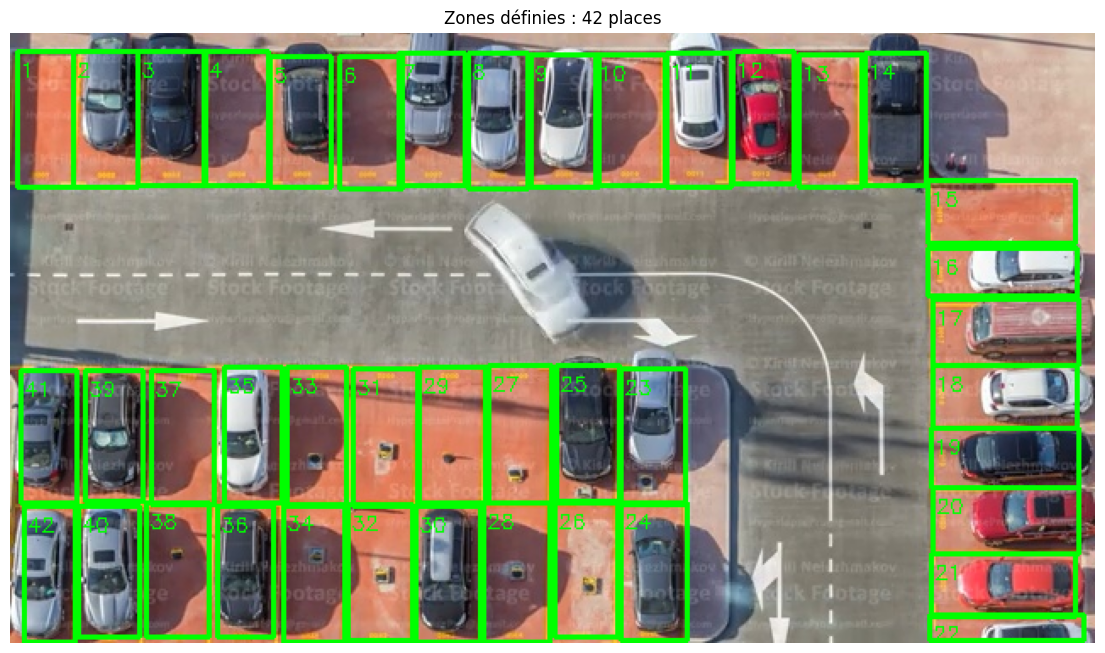

In [31]:
# Vérification visuelle des zones

import cv2
import matplotlib.pyplot as plt

FRAME_PATH = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\frame_ref2.jpg'

PLACES = [[4, 11, 37, 91], [37, 11, 75, 91], [75, 11, 114, 90], [115, 11, 152, 90], [153, 14, 189, 91], [194, 14, 231, 92], [229, 12, 268, 90], [270, 12, 305, 92], [307, 13, 347, 91], [345, 13, 386, 90], [387, 12, 425, 91], [426, 11, 462, 89], [465, 13, 502, 91], [504, 12, 540, 90], [541, 87, 628, 124], [541, 127, 629, 155], [544, 157, 630, 196], [544, 196, 629, 233], [543, 233, 630, 268], [544, 268, 630, 307], [543, 307, 628, 344], [542, 343, 633, 358], [360, 198, 398, 278], [360, 277, 399, 358], [322, 196, 359, 276], [321, 277, 358, 356], [282, 196, 319, 277], [279, 277, 318, 359], [241, 197, 280, 277], [239, 279, 277, 359], [202, 198, 240, 279], [199, 278, 237, 358], [163, 197, 198, 279], [161, 278, 197, 359], [126, 197, 160, 277], [122, 279, 155, 356], [83, 199, 120, 278], [80, 277, 117, 356], [44, 199, 78, 276], [40, 279, 76, 356], [6, 199, 39, 277], [8, 279, 38, 359]]

frame = cv2.imread(FRAME_PATH)
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

for i, (x1, y1, x2, y2) in enumerate(PLACES):
    cv2.rectangle(frame_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(frame_rgb, str(i+1), (x1+2, y1+15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

plt.figure(figsize=(14, 8))
plt.imshow(frame_rgb)
plt.title(f"Zones définies : {len(PLACES)} places")
plt.axis('off')
plt.show()

In [32]:
# Cellule Phase 3 — Dashboard temps réel ResNet-50

import cv2
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import torch.nn as nn
from PIL import Image
import numpy as np

# --- Paramètres ---
VIDEO_PATH  = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\parking.mp4'
OUTPUT_PATH = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\parking_final.mp4'
MODEL_PATH  = r'C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\models\checkpoint_actuel.pth'

PLACES = [[4, 11, 37, 91], [37, 11, 75, 91], [75, 11, 114, 90], [115, 11, 152, 90], [153, 14, 189, 91], [194, 14, 231, 92], [229, 12, 268, 90], [270, 12, 305, 92], [307, 13, 347, 91], [345, 13, 386, 90], [387, 12, 425, 91], [426, 11, 462, 89], [465, 13, 502, 91], [504, 12, 540, 90], [541, 87, 628, 124], [541, 127, 629, 155], [544, 157, 630, 196], [544, 196, 629, 233], [543, 233, 630, 268], [544, 268, 630, 307], [543, 307, 628, 344], [542, 343, 633, 358], [360, 198, 398, 278], [360, 277, 399, 358], [322, 196, 359, 276], [321, 277, 358, 356], [282, 196, 319, 277], [279, 277, 318, 359], [241, 197, 280, 277], [239, 279, 277, 359], [202, 198, 240, 279], [199, 278, 237, 358], [163, 197, 198, 279], [161, 278, 197, 359], [126, 197, 160, 277], [122, 279, 155, 356], [83, 199, 120, 278], [80, 277, 117, 356], [44, 199, 78, 276], [40, 279, 76, 356], [6, 199, 39, 277], [8, 279, 38, 359]]

# --- Charger ResNet-50 ---
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()
print(f"✅ Modèle chargé sur {device}")

# --- Transform ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# --- Pipeline vidéo ---
cap    = cv2.VideoCapture(VIDEO_PATH)
fps    = int(cap.get(cv2.CAP_PROP_FPS))
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
out    = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))

print(f"✅ Vidéo : {width}x{height} | {fps} FPS | {total} frames")

frame_idx = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    n_libre    = 0
    n_occupee  = 0

    for i, (x1, y1, x2, y2) in enumerate(PLACES):
        # Extraire le crop
        crop = frame[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        # Classifier avec ResNet-50
        img    = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        tensor = transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(tensor)
            pred   = output.argmax(1).item()  # 0=libre, 1=occupée

        # Couleur selon classification
        if pred == 0:  # libre
            color = (0, 255, 0)   # vert
            n_libre += 1
        else:          # occupée
            color = (0, 0, 255)   # rouge
            n_occupee += 1

        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)

    # Dashboard
    cv2.rectangle(frame, (0, 0), (300, 60), (0, 0, 0), -1)
    cv2.putText(frame, f"Libres   : {n_libre}",
                (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    cv2.putText(frame, f"Occupees : {n_occupee}",
                (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

    out.write(frame)
    frame_idx += 1

    if frame_idx % 10 == 0:
        print(f"  Frame {frame_idx}/{total} ({frame_idx/total*100:.1f}%)")

cap.release()
out.release()
print(f"\n✅ Vidéo finale : {OUTPUT_PATH}")

✅ Modèle chargé sur cpu
✅ Vidéo : 640x360 | 25 FPS | 330 frames
  Frame 10/330 (3.0%)
  Frame 20/330 (6.1%)
  Frame 30/330 (9.1%)
  Frame 40/330 (12.1%)
  Frame 50/330 (15.2%)
  Frame 60/330 (18.2%)
  Frame 70/330 (21.2%)
  Frame 80/330 (24.2%)
  Frame 90/330 (27.3%)
  Frame 100/330 (30.3%)
  Frame 110/330 (33.3%)
  Frame 120/330 (36.4%)
  Frame 130/330 (39.4%)
  Frame 140/330 (42.4%)
  Frame 150/330 (45.5%)
  Frame 160/330 (48.5%)
  Frame 170/330 (51.5%)
  Frame 180/330 (54.5%)
  Frame 190/330 (57.6%)
  Frame 200/330 (60.6%)
  Frame 210/330 (63.6%)
  Frame 220/330 (66.7%)
  Frame 230/330 (69.7%)
  Frame 240/330 (72.7%)
  Frame 250/330 (75.8%)
  Frame 260/330 (78.8%)
  Frame 270/330 (81.8%)
  Frame 280/330 (84.8%)
  Frame 290/330 (87.9%)
  Frame 300/330 (90.9%)
  Frame 310/330 (93.9%)
  Frame 320/330 (97.0%)
  Frame 330/330 (100.0%)

✅ Vidéo finale : C:\Users\PC\Desktop\school\master\M1\PROJET PERSO\IA\gestion_parking\data\parking_final.mp4
